# Stage at diagnosis and five-year relative survival, oral cavity and pharynx

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shah-pushti/oral-cancer-figures/blob/main/notebooks/stage-and-survival.ipynb)

This notebook rebuilds the stage chart of the article [Oral cancer: estimated new cases by country and five-year survival by stage at diagnosis](https://shah-pushti.github.io/oral-cancer-in-numbers.html). The data are from the SEER registries in the United States, for invasive cancer of the oral cavity and pharynx diagnosed from 2007 to 2013. Relative survival is the observed survival of the patients divided by the survival expected in people of the same age and sex in the general population.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Read the data from this repository; in Colab, read it from GitHub.
BASE = Path("..") if Path("../data").exists() else None
RAW = "https://raw.githubusercontent.com/shah-pushti/oral-cancer-figures/main/"

def load(name):
    return pd.read_csv(BASE / "data" / name if BASE else RAW + "data/" + name)

INK, BURGUNDY, STEEL, PAPER = "#231920", "#6E1A2D", "#3F6068", "#F7F8F5"
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "text.color": INK, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
})
OUT = Path("../figures") if BASE else Path("figures")
OUT.mkdir(exist_ok=True)

In [2]:
df = load("seer-oral-pharynx-stage-survival-2007-2013.csv")
df

,stage,description,share_of_cases_percent,five_year_relative_survival_percent,source
0,Localised,not spread beyond the site of origin,30,83.7,SEER CSR 1975-2014 Table 20.10
1,Regional,spread to nearby tissue or regional lymph nodes,47,64.2,SEER CSR 1975-2014 Table 20.10
2,Distant,spread to distant parts of the body,19,38.5,SEER CSR 1975-2014 Table 20.10
3,Unstaged,no stage recorded,4,47.9,SEER CSR 1975-2014 Table 20.10
4,All stages,all cases,100,64.5,SEER CSR 1975-2014 Table 20.10


Each square below is one of 100 cases, shaded by stage at diagnosis. Stage is an ordered category, so one hue runs from light (localised) to dark (distant); unstaged cases are outlined.

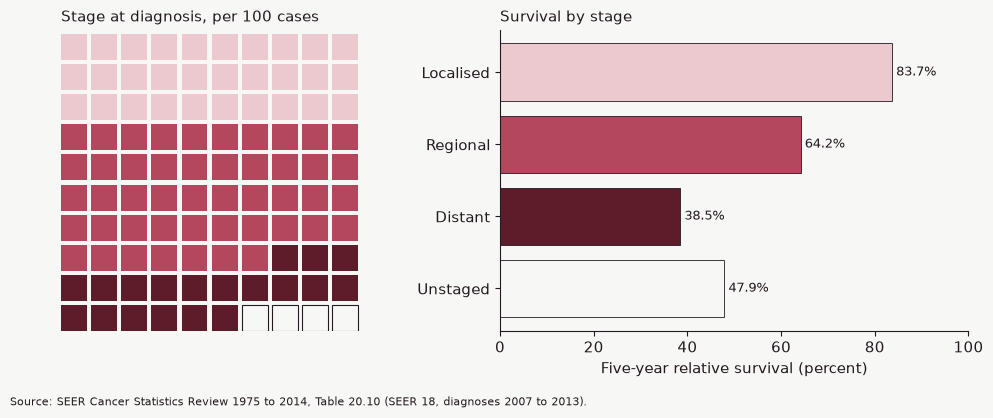

In [3]:
stages = df[df["stage"] != "All stages"].reset_index(drop=True)
shades = {"Localised": "#EBC9CF", "Regional": "#B4475E", "Distant": "#5E1C2B", "Unstaged": None}
cells = [s for s, n in zip(stages["stage"], stages["share_of_cases_percent"]) for _ in range(int(n))]
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.2]})
for i, s in enumerate(cells):
    x, y = i % 10, 9 - i // 10
    c = shades[s]
    a.add_patch(plt.Rectangle((x, y), 0.86, 0.86, facecolor=c or "none", edgecolor=c or INK, linewidth=0 if c else 0.8))
a.set_xlim(0, 10); a.set_ylim(0, 10); a.set_aspect("equal"); a.axis("off")
a.set_title("Stage at diagnosis, per 100 cases", loc="left", fontsize=11)
b.barh(stages["stage"][::-1], stages["five_year_relative_survival_percent"][::-1],
       color=[shades[s] or "none" for s in stages["stage"][::-1]], edgecolor=INK, linewidth=0.6)
for y, v in enumerate(stages["five_year_relative_survival_percent"][::-1]):
    b.text(v, y, f" {v}%", va="center", fontsize=9)
b.set_xlim(0, 100); b.set_xlabel("Five-year relative survival (percent)")
b.set_title("Survival by stage", loc="left", fontsize=11)
fig.text(0.01, -0.03, "Source: SEER Cancer Statistics Review 1975 to 2014, Table 20.10 (SEER 18, diagnoses 2007 to 2013).", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "stage-and-survival.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT / "stage-and-survival.svg", bbox_inches="tight")

As a consistency check on the transcribed values, the share-weighted average of the stage-specific survival figures is compared with the all-stages figure reported by SEER (64.5 percent).

In [4]:
weighted = (stages["share_of_cases_percent"] * stages["five_year_relative_survival_percent"]).sum() / 100
print(f"Share-weighted survival: {weighted:.1f}%  (SEER all stages: 64.5%)")

Share-weighted survival: 64.5%  (SEER all stages: 64.5%)


## Sources

- Surveillance, Epidemiology, and End Results Program. SEER Cancer Statistics Review 1975 to 2014, Table 20.10. https://seer.cancer.gov/archive/csr/1975_2014/results_single/sect_20_table.10.pdf